# 03 - Business analysis



**Purpose:** answer the main business questions behind the dashboard.

1. How did the core KPIs change year by year?
2. Where did growth come from: existing cities or new ones?
3. Why did Forkly move from losses to a positive contribution margin?
4. Do customers stay? (cohort retention)
5. Does Forkly Plus change customer behaviour?
6. Do promotions bring customers who come back?
7. How much do late deliveries cost in ratings and repeat orders?
8. How does weather affect demand and delivery?
9. Which marketing channels bring customers most cheaply?
10. Which cuisines and restaurants drive GMV?
11. Who are the most valuable customers today? (RFM)

**Input:** `Forkly/Data_clean/*.csv`
**Output:** charts in `Forkly/output/figures/`, summary tables in `Forkly/output/tables/` (used by the dashboard)



## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# works whether the notebook runs from the Forkly folder or from Forkly/notebooks
BASE = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
CLEAN_DIR = BASE / "Data_clean"
FIG_DIR = BASE / "output" / "figures"
TAB_DIR = BASE / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# shared chart style (Forkly/src/theme.py)
sys.path.append(str(BASE / "src"))
from theme import *
apply_theme()

In [2]:
DATE_COLS = {
    "calendar": ["date"],
    "cities": ["launch_date"],
    "weather_daily": ["date"],
    "customers": ["signup_date", "signup_month"],
    "restaurants": ["onboarded_date", "offboarded_date"],
    "couriers": ["join_date"],
    "promotions": ["start_date", "end_date"],
    "subscriptions": ["start_date", "end_date"],
    "orders": ["order_datetime", "order_date", "month"],
    "deliveries": ["pickup_datetime", "dropoff_datetime"],
    "reviews": ["review_datetime"],
    "support_tickets": ["created_datetime", "resolved_datetime"],
    "marketing_spend": ["date"],
}

df = {}
for path in sorted(CLEAN_DIR.glob("*.csv")):
    if path.stem != "cleaning_log":
        df[path.stem] = pd.read_csv(path, parse_dates=DATE_COLS.get(path.stem, []))

orders, order_items, deliveries = df["orders"], df["order_items"], df["deliveries"]
customers, restaurants, reviews = df["customers"], df["restaurants"], df["reviews"]
cities, couriers, tickets = df["cities"], df["couriers"], df["support_tickets"]
mkt, weather, subs, promos = df["marketing_spend"], df["weather_daily"], df["subscriptions"], df["promotions"]

print({k: f"{len(v):,}" for k, v in df.items()})

{'calendar': '1,826', 'cities': '12', 'couriers': '5,369', 'customers': '45,000', 'deliveries': '282,862', 'marketing_spend': '10,956', 'menu_items': '18,454', 'order_items': '662,291', 'orders': '300,000', 'promotions': '120', 'restaurants': '2,889', 'reviews': '132,720', 'subscriptions': '15,287', 'support_tickets': '13,365', 'weather_daily': '21,912'}


In [3]:
# order-level table with everything needed for money metrics
od = (orders
      .merge(cities[["city_id", "city", "launch_date"]], on="city_id", how="left")
      .merge(restaurants[["restaurant_id", "cuisine", "commission_rate"]], on="restaurant_id", how="left")
      .merge(promos[["promo_id", "funded_by"]], on="promo_id", how="left")
      .merge(deliveries[["order_id", "courier_pay", "delivery_minutes", "minutes_vs_promise", "is_late"]],
             on="order_id", how="left")
      .merge(reviews[["order_id", "food_rating", "delivery_rating"]], on="order_id", how="left"))

refunds = tickets.groupby("order_id")["refund_amount"].sum()
od["refund_amount"] = od["order_id"].map(refunds).fillna(0)

# money per order (cancelled orders bring no revenue)
platform_share = od["funded_by"].map({"Platform": 1.0, "Shared": 0.5, "Restaurant": 0.0}).fillna(0)
od["commission"] = od["items_subtotal"] * od["commission_rate"]
od["platform_discount"] = od["discount_amount"] * platform_share
od["net_revenue"] = od["commission"] + od["delivery_fee"] + od["service_fee"] - od["platform_discount"]
od["contribution"] = od["net_revenue"] - od["courier_pay"].fillna(0) - od["refund_amount"]

done = od[~od["is_cancelled"]].copy()
print(f"{len(od):,} orders, {len(done):,} not cancelled")

300,000 orders, 282,862 not cancelled


## 1. Yearly KPI scorecard

In [4]:
g = done.groupby("year")
kpi = pd.DataFrame({
    "orders": od.groupby("year").size(),
    "gmv": g["items_subtotal"].sum(),
    "aov": g["items_subtotal"].mean(),
    "active_customers": od.groupby("year")["customer_id"].nunique(),
    "new_customers": customers.groupby("signup_year").size(),
    "net_revenue": g["net_revenue"].sum(),
    "contribution": g["contribution"].sum(),
    "cancel_rate_%": od.groupby("year")["is_cancelled"].mean() * 100,
    "late_rate_%": g["is_late"].mean() * 100,
    "avg_delivery_min": g["delivery_minutes"].mean(),
    "delivery_rating": g["delivery_rating"].mean(),
    "food_rating": g["food_rating"].mean(),
    "promo_order_%": od.groupby("year")["has_promo"].mean() * 100,
    "plus_order_%": od.groupby("year")["is_plus_order"].mean() * 100,
    "grocery_order_%": od.groupby("year")["vertical"].apply(lambda s: (s == "Grocery").mean() * 100),
    "marketing_spend": mkt.groupby(mkt["date"].dt.year)["spend_eur"].sum(),
})
kpi["take_rate_%"] = kpi["net_revenue"] / kpi["gmv"] * 100
kpi["contribution_margin_%"] = kpi["contribution"] / kpi["gmv"] * 100
kpi["orders_per_customer"] = kpi["orders"] / kpi["active_customers"]
kpi["cac"] = kpi["marketing_spend"] / kpi["new_customers"]
kpi["gmv_growth_%"] = kpi["gmv"].pct_change() * 100

kpi.to_csv(TAB_DIR / "kpi_by_year.csv")
kpi.T.round(2)

,2021,2022,2023,2024,2025
orders,36000,60000,61000,69000,74000
gmv,"728,358.01","1,224,139.97","1,423,775.07","1,823,040.95","2,040,859.89"
aov,21.66,22.50,24.72,27.66,28.60
active_customers,10362,20746,22326,25838,28909
new_customers,12000,13000,6500,7500,6000
net_revenue,"219,825.96","429,613.45","533,183.36","637,455.49","658,960.95"
contribution,"-34,686.20","-10,525.48","86,159.07","139,634.71","130,477.12"
cancel_rate_%,6.60,9.34,5.60,4.48,3.58
late_rate_%,13.98,32.02,11.18,7.21,5.09
avg_delivery_min,35.25,39.13,34.46,32.38,30.73


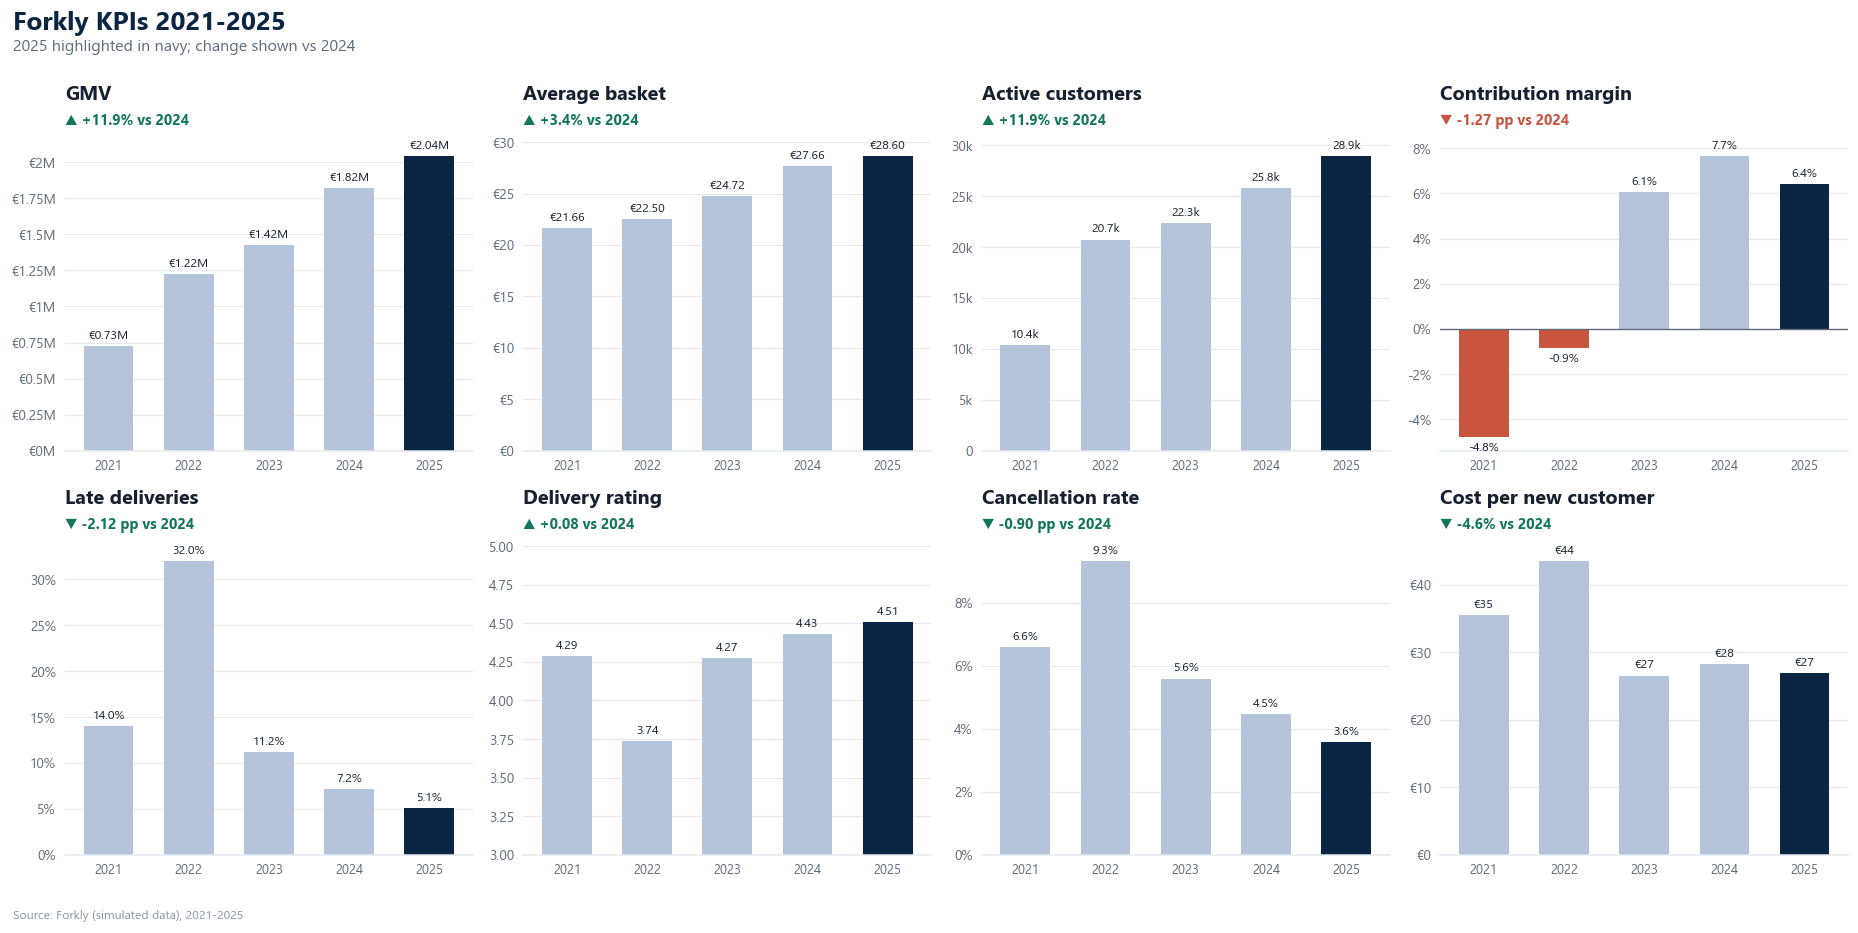

In [5]:
# main KPIs as small multiples
show = [("gmv", "GMV", eur_m, lambda v: f"€{v / 1e6:.2f}M", True),
        ("aov", "Average basket", eur, lambda v: fmt_eur(v), True),
        ("active_customers", "Active customers", thousands, lambda v: f"{v / 1e3:.1f}k", True),
        ("contribution_margin_%", "Contribution margin", pct, lambda v: f"{v:.1f}%", True),
        ("late_rate_%", "Late deliveries", pct, lambda v: f"{v:.1f}%", False),
        ("delivery_rating", "Delivery rating", None, lambda v: f"{v:.2f}", True),
        ("cancel_rate_%", "Cancellation rate", pct, lambda v: f"{v:.1f}%", False),
        ("cac", "Cost per new customer", eur, lambda v: fmt_eur(v, 0), False)]

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, (col, name, axis_fmt, label_fmt, higher_is_better) in zip(axes.flat, show):
    vals = kpi[col]
    colors = [ALERT if v < 0 else (NAVY if y == 2025 else NAVY_LIGHT) for y, v in vals.items()]
    bars = ax.bar(kpi.index, vals, color=colors, width=0.62)
    label_bars(ax, bars, label_fmt, fontsize=8)
    if axis_fmt is not None:
        ax.yaxis.set_major_formatter(axis_fmt)
    ax.set_xticks(kpi.index); ax.tick_params(axis="x", labelsize=8.5)
    if col == "delivery_rating":
        ax.set_ylim(3, 5)
    if col == "contribution_margin_%":
        zero_line(ax)
    change = vals.iloc[-1] - vals.iloc[-2]
    good = (change > 0) == higher_is_better
    unit = " pp" if col.endswith("%") else ""
    txt = (f"{change / vals.iloc[-2]:+.1%} vs 2024" if not unit and col != "delivery_rating"
           else f"{change:+.2f}{unit} vs 2024")
    title(ax, name, ("▲ " if change > 0 else "▼ ") + txt, subtitle_color=GREEN_DARK if good else ALERT,
          subtitle_weight="bold")
fig_header(fig, "Forkly KPIs 2021-2025", "2025 highlighted in navy; change shown vs 2024", y=1.04)
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_kpi_multiples.png")
plt.show()

## 2. Where did growth come from?
**Launch cities** are the four cities Forkly started in (Vilnius, Kaunas, Riga, Tallinn, January 2021). **Expansion cities** are the eight added from 2022 onwards.

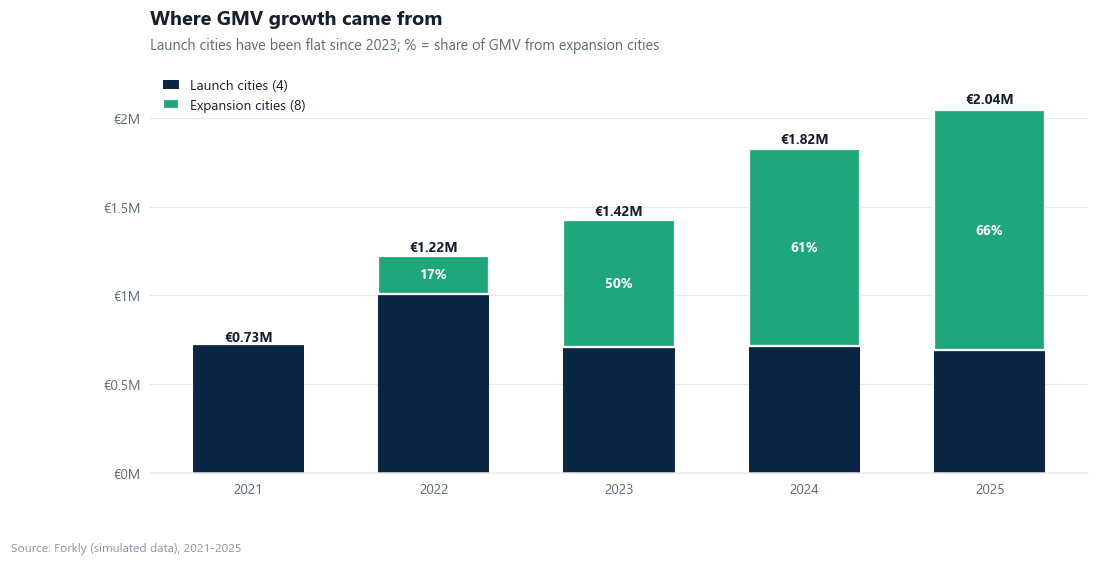

city_group,Launch cities,Expansion cities
year,,
2021,100.00,0.00
2022,82.50,17.50
2023,50.00,50.00
2024,39.40,60.60
2025,33.90,66.10


In [6]:
city_year = done.groupby(["year", "city", "launch_date"])["items_subtotal"].sum().reset_index()
city_year["city_group"] = np.where(city_year["launch_date"].dt.year == 2021, "Launch cities", "Expansion cities")
growth = city_year.pivot_table(index="year", columns="city_group", values="items_subtotal", aggfunc="sum",
                               fill_value=0)[["Launch cities", "Expansion cities"]]
share = growth.div(growth.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4.8))
b1 = ax.bar(growth.index, growth["Launch cities"], color=NAVY, width=0.6, label="Launch cities (4)")
b2 = ax.bar(growth.index, growth["Expansion cities"], bottom=growth["Launch cities"], color=GREEN, width=0.6,
            label="Expansion cities (8)", edgecolor=BG, linewidth=1.5)
for x in growth.index:
    total = growth.loc[x].sum()
    ax.text(x, total * 1.02, f"€{total / 1e6:.2f}M", ha="center", fontsize=9, weight="bold")
    if share.loc[x, "Expansion cities"] > 8:
        ax.text(x, growth.loc[x, "Launch cities"] + growth.loc[x, "Expansion cities"] / 2,
                f"{share.loc[x, 'Expansion cities']:.0f}%", ha="center", va="center", color=BG, fontsize=9, weight="bold")
ax.yaxis.set_major_formatter(eur_m); ax.set_xticks(growth.index); ax.set_ylim(0, growth.sum(axis=1).max() * 1.12)
legend_top(ax, ncol=1, loc="upper left")
title(ax, "Where GMV growth came from", "Launch cities have been flat since 2023; % = share of GMV from expansion cities")
source_note(fig)
save_fig(fig, FIG_DIR / "03_growth_by_city_group.png")
plt.show()

growth.to_csv(TAB_DIR / "gmv_by_city_group.csv")
share.round(1)

In [7]:
# GMV change of each city between years
city_gmv = done.pivot_table(index="city", columns="year", values="items_subtotal", aggfunc="sum", fill_value=0)
city_gmv["change_2024_2025_%"] = (city_gmv[2025] / city_gmv[2024].replace(0, np.nan) - 1) * 100
city_gmv.to_csv(TAB_DIR / "gmv_by_city_year.csv")
city_gmv.sort_values(2025, ascending=False).round(0)

year,2021,2022,2023,2024,2025,change_2024_2025_%
city,,,,,,
Warsaw,0.00,"117,769.00","454,836.00","495,424.00","471,510.00",-5.00
Krakow,0.00,0.00,"126,563.00","255,874.00","249,127.00",-3.00
Helsinki,0.00,0.00,0.00,"148,178.00","220,197.00",49.00
Riga,"221,886.00","300,144.00","215,338.00","216,298.00","209,138.00",-3.00
Vilnius,"205,881.00","292,617.00","211,021.00","209,326.00","192,394.00",-8.00
Tallinn,"177,591.00","244,800.00","171,811.00","173,260.00","175,132.00",1.00
Gdansk,0.00,0.00,0.00,"61,933.00","172,132.00",178.00
Kaunas,"123,001.00","172,407.00","114,261.00","119,719.00","116,052.00",-3.00
Klaipeda,0.00,"65,166.00","77,277.00","79,900.00","75,379.00",-6.00


## 3. Unit economics: from losses to profit
Average money per non-cancelled order. Revenue = commission + delivery fee + service fee; costs = discounts Forkly pays for, courier pay and refunds.

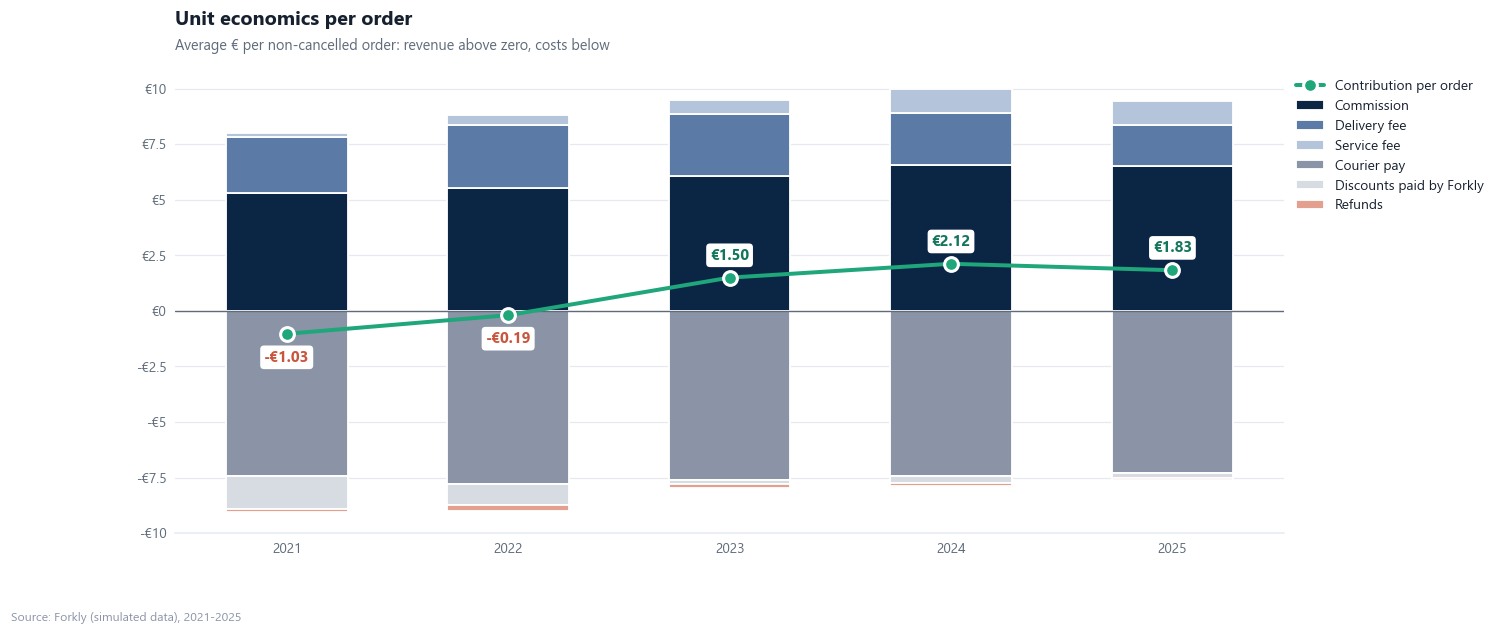

,commission,delivery_fee,service_fee,platform_discount,courier_pay,refund_amount,contribution
year,,,,,,,
2021,5.32,2.52,0.18,1.49,7.43,0.14,-1.03
2022,5.53,2.82,0.46,0.92,7.80,0.29,-0.19
2023,6.07,2.76,0.64,0.21,7.59,0.17,1.50
2024,6.54,2.35,1.10,0.32,7.41,0.15,2.12
2025,6.51,1.85,1.09,0.21,7.29,0.12,1.83


In [8]:
ue = done.groupby("year")[["commission", "delivery_fee", "service_fee", "platform_discount",
                           "courier_pay", "refund_amount", "contribution"]].mean()
ue.to_csv(TAB_DIR / "unit_economics_per_order.csv")

parts = ue.copy()
for c in ["platform_discount", "courier_pay", "refund_amount"]:
    parts[c] = -parts[c]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(parts))
pos_cols = [("commission", NAVY, "Commission"), ("delivery_fee", STEEL, "Delivery fee"),
            ("service_fee", NAVY_LIGHT, "Service fee")]
neg_cols = [("courier_pay", GREY, "Courier pay"), ("platform_discount", GREY_LIGHT, "Discounts paid by Forkly"),
            ("refund_amount", "#E3A08F", "Refunds")]
for cols in (pos_cols, neg_cols):
    b = np.zeros(len(parts))
    for c, color, label in cols:
        ax.bar(x, parts[c], bottom=b, color=color, width=0.55, label=label, edgecolor=BG, linewidth=1.2)
        b += parts[c].values
ax.plot(x, parts["contribution"], color=GREEN, marker="o", ms=9, lw=2.6, label="Contribution per order",
        markeredgecolor=BG, markeredgewidth=2, zorder=5)
for xi, v in zip(x, parts["contribution"]):
    ax.annotate(fmt_eur(v), (xi, v), xytext=(0, 12 if v >= 0 else -18), textcoords="offset points", ha="center",
                fontsize=10, weight="bold", color=GREEN_DARK if v >= 0 else ALERT,
                bbox=dict(boxstyle="round,pad=0.25", fc=BG, ec="none"))
zero_line(ax)
ax.set_xticks(x, parts.index); ax.yaxis.set_major_formatter(eur)
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
title(ax, "Unit economics per order", "Average € per non-cancelled order: revenue above zero, costs below")
source_note(fig)
save_fig(fig, FIG_DIR / "03_unit_economics.png")
plt.show()
ue.round(2)

In [9]:
# what moved the contribution most between 2021 and 2025
delta = (parts.loc[2025] - parts.loc[2021]).drop("contribution").sort_values()
print("Change per order 2021 -> 2025 (€):")
print(delta.round(2).to_string())
print(f"Total change in contribution per order: €{parts.loc[2025, 'contribution'] - parts.loc[2021, 'contribution']:.2f}")

Change per order 2021 -> 2025 (€):
delivery_fee        -0.68
refund_amount        0.03
courier_pay          0.14
service_fee          0.91
commission           1.19
platform_discount    1.28
Total change in contribution per order: €2.86


## 4. Customer retention by signup cohort

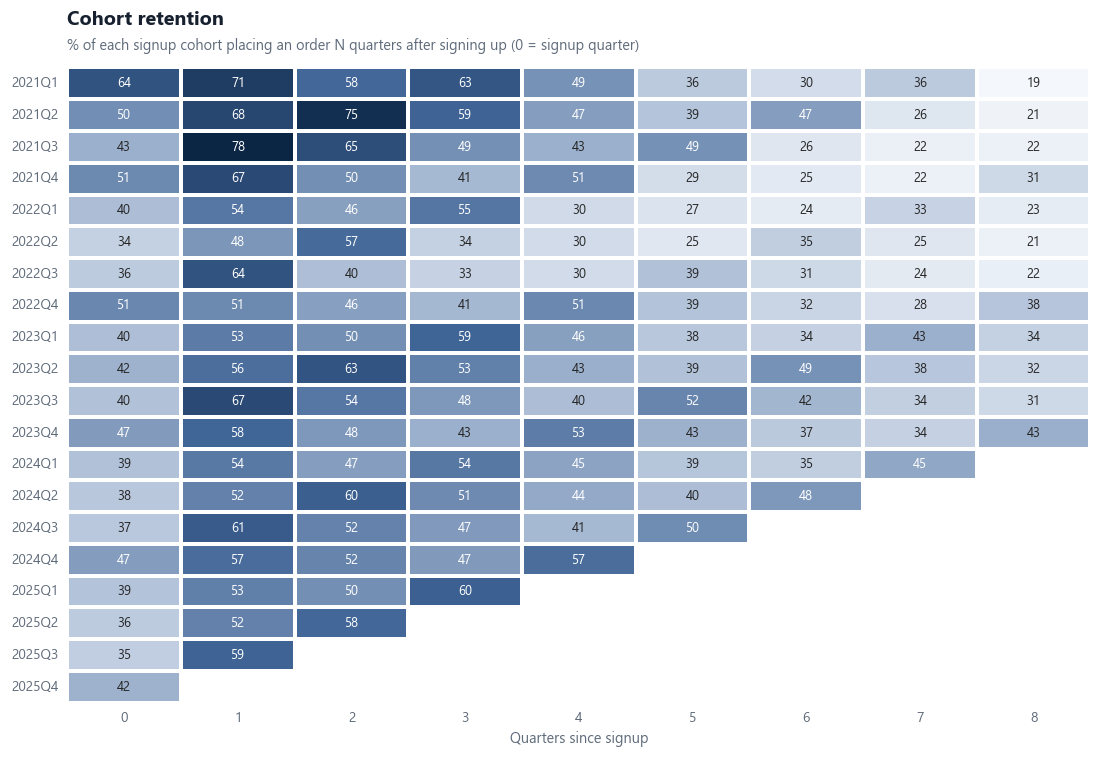

In [10]:
ord_q = orders[["customer_id", "order_datetime"]].merge(customers[["customer_id", "signup_date"]], on="customer_id")
ord_q["cohort"] = ord_q["signup_date"].dt.to_period("Q")
ord_q["order_q"] = ord_q["order_datetime"].dt.to_period("Q")
ord_q["q_since"] = (ord_q["order_q"] - ord_q["cohort"]).apply(lambda d: d.n)

cohort_size = customers.groupby(customers["signup_date"].dt.to_period("Q")).size()
active = ord_q.groupby(["cohort", "q_since"])["customer_id"].nunique().unstack()
retention = active.div(cohort_size, axis=0) * 100
retention = retention.loc[:, 0:8]
retention.index = retention.index.astype(str)
retention.to_csv(TAB_DIR / "cohort_retention_quarterly.csv")

fig, ax = plt.subplots(figsize=(12, 7.5))
sns.heatmap(retention, cmap=CMAP_NAVY, annot=True, fmt=".0f", cbar=False, linewidths=1.5, linecolor=BG,
            annot_kws={"fontsize": 8.5}, ax=ax)
clean_heatmap(ax)
title(ax, "Cohort retention", "% of each signup cohort placing an order N quarters after signing up (0 = signup quarter)")
ax.set_xlabel("Quarters since signup"); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
save_fig(fig, FIG_DIR / "03_cohort_retention.png")
plt.show()

In [11]:
# year-to-year retention: of customers who ordered in year Y, how many ordered again in Y+1?
buyers = orders.groupby("year")["customer_id"].apply(set)
yoy = pd.Series({y: len(buyers[y] & buyers[y + 1]) / len(buyers[y]) * 100 for y in range(2021, 2025)},
                name="retained_next_year_%")

# new vs returning orders
first_year = orders.groupby("customer_id")["year"].min().rename("first_year")
nr = orders.join(first_year, on="customer_id")
nr["type"] = np.where(nr["year"] == nr["first_year"], "New customer", "Returning customer")
nr_share = pd.crosstab(nr["year"], nr["type"], normalize="index") * 100

print(yoy.round(1))
nr_share.round(1)

2021   90.10
2022   70.90
2023   67.90
2024   68.00
Name: retained_next_year_%, dtype: float64


type,New customer,Returning customer
year,,
2021,100.00,0.00
2022,57.30,42.70
2023,44.70,55.30
2024,39.60,60.40
2025,29.50,70.50


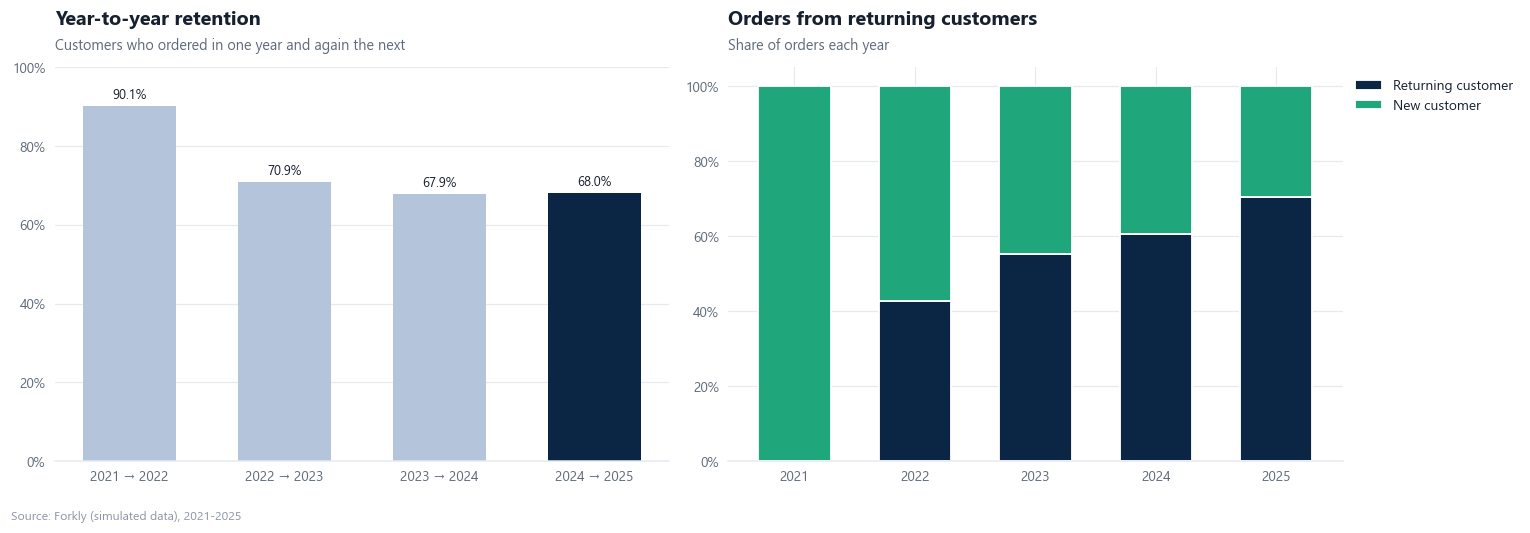

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
bars = axes[0].bar(yoy.index, yoy.values, color=[NAVY_LIGHT, NAVY_LIGHT, NAVY_LIGHT, NAVY], width=0.6)
label_bars(axes[0], bars, "{:.1f}%")
axes[0].set_xticks(yoy.index, [f"{y} → {y + 1}" for y in yoy.index])
axes[0].yaxis.set_major_formatter(pct); axes[0].set_ylim(0, 100)
title(axes[0], "Year-to-year retention", "Customers who ordered in one year and again the next")

nr_share[["Returning customer", "New customer"]].plot(kind="bar", stacked=True, color=[NAVY, GREEN], ax=axes[1],
                                                      width=0.6, edgecolor=BG, linewidth=1.2)
axes[1].yaxis.set_major_formatter(pct); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(bbox_to_anchor=(1, 1), loc="upper left")
title(axes[1], "Orders from returning customers", "Share of orders each year")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_retention_yoy.png")
plt.show()

## 5. Forkly Plus
Compare 2025 customers who had at least one Plus order with customers who had none.

In [13]:
o25 = done[done["year"] == 2025]
cust25 = o25.groupby("customer_id").agg(orders=("order_id", "size"), aov=("items_subtotal", "mean"),
                                        delivery_fee=("delivery_fee", "mean"), plus=("is_plus_order", "max"),
                                        contribution=("contribution", "sum"))
cust25["group"] = np.where(cust25["plus"], "Plus member", "Non-member")
plus_cmp = cust25.groupby("group").agg(customers=("orders", "size"), orders_per_customer=("orders", "mean"),
                                       aov=("aov", "mean"), avg_delivery_fee=("delivery_fee", "mean"),
                                       contribution_per_customer=("contribution", "mean"))
plus_cmp.to_csv(TAB_DIR / "plus_vs_non_member_2025.csv")
plus_cmp.round(2)

,customers,orders_per_customer,aov,avg_delivery_fee,contribution_per_customer
group,,,,,
Non-member,18758,1.79,28.85,2.82,5.01
Plus member,9663,3.92,28.56,0.86,3.77


In [14]:
# subscriptions started, cancelled and active at year end
sub_year = pd.DataFrame({
    "new_subscriptions": subs.groupby(subs["start_date"].dt.year).size(),
    "cancelled": subs.groupby(subs["end_date"].dt.year).size(),
})
sub_year["active_at_year_end"] = [((subs["start_date"] <= f"{y}-12-31") &
                                   (subs["end_date"].isna() | (subs["end_date"] > f"{y}-12-31"))).sum()
                                  for y in sub_year.index]
sub_year = sub_year.fillna(0).astype(int)
sub_year.to_csv(TAB_DIR / "plus_subscriptions_by_year.csv")
sub_year

,new_subscriptions,cancelled,active_at_year_end
2023,1155,99,1056
2024,6919,1451,6524
2025,7213,4821,8916


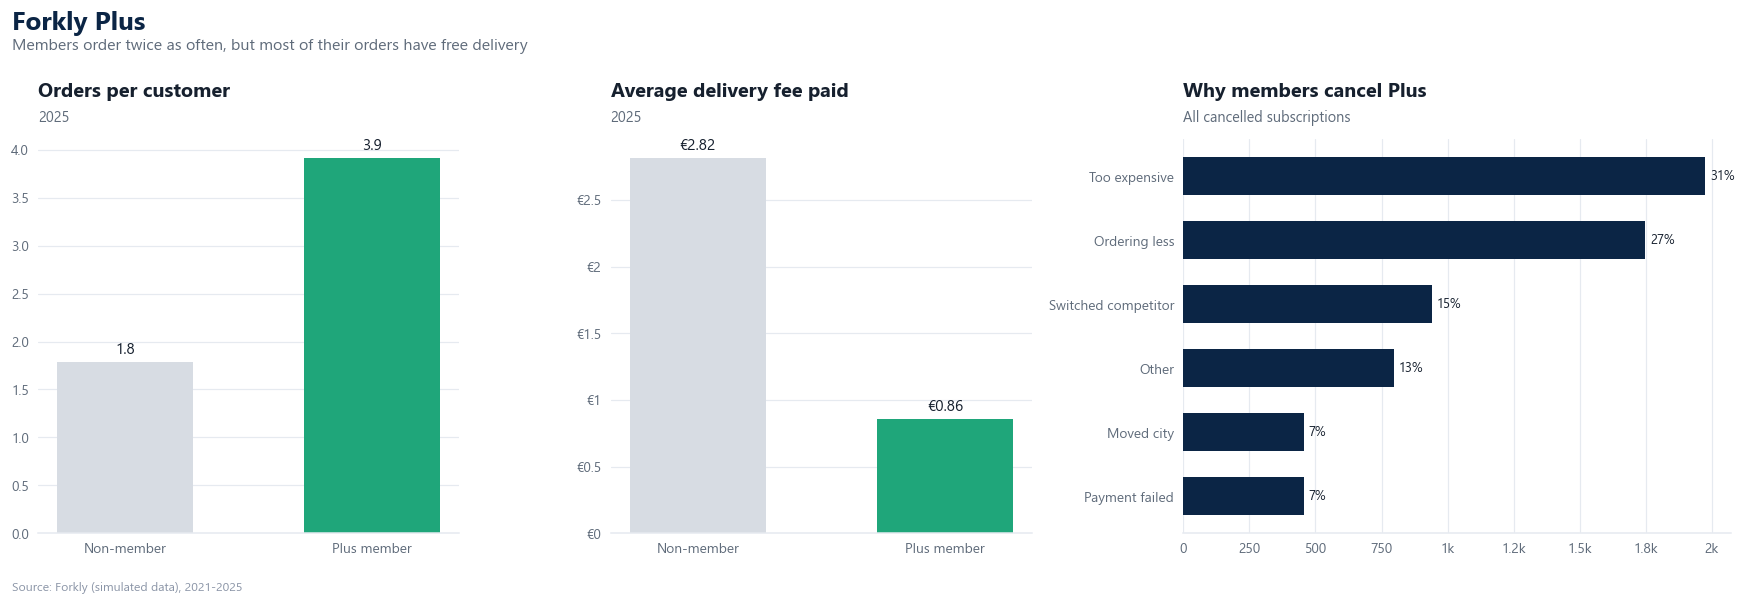

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, col, name, f in [(axes[0], "orders_per_customer", "Orders per customer", "{:.1f}"),
                         (axes[1], "avg_delivery_fee", "Average delivery fee paid", "€{:.2f}")]:
    bars = ax.bar(["Non-member", "Plus member"], plus_cmp.loc[["Non-member", "Plus member"], col],
                  color=[GREY_LIGHT, GREEN], width=0.55)
    label_bars(ax, bars, f, fontsize=10)
    title(ax, name, "2025")
axes[1].yaxis.set_major_formatter(eur)

reasons = subs["cancel_reason"].value_counts().sort_values()
bars = axes[2].barh(reasons.index, reasons.values, color=NAVY, height=0.6)
label_hbars(axes[2], bars, lambda v: f"{v / reasons.sum():.0%}")
hbar_style(axes[2]); axes[2].xaxis.set_major_formatter(thousands)
title(axes[2], "Why members cancel Plus", "All cancelled subscriptions")
fig_header(fig, "Forkly Plus", "Members order twice as often, but most of their orders have free delivery", y=1.06)
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_plus.png")
plt.show()

## 6. Promotions: do discounted first orders create loyal customers?
Repeat rate = share of customers who place another order within 90 days of their first order.

In [16]:
ranked = orders.sort_values("order_datetime").assign(order_no=lambda d: d.groupby("customer_id").cumcount() + 1)
first = ranked[ranked["order_no"] == 1][["customer_id", "order_datetime", "has_promo", "year"]]
second = ranked[ranked["order_no"] == 2].set_index("customer_id")["order_datetime"].rename("second_order")
first = first.join(second, on="customer_id")
first["repeat_90d"] = (first["second_order"] - first["order_datetime"]).dt.days <= 90
first = first[first["order_datetime"] < "2025-10-01"]   # need 90 days of follow-up

promo_repeat = (first.pivot_table(index="year", columns="has_promo", values="repeat_90d", aggfunc="mean") * 100)
promo_repeat.columns = ["First order without promo", "First order with promo"]

promo_cost = done.groupby("year").agg(discount_total=("discount_amount", "sum"),
                                      paid_by_forkly=("platform_discount", "sum"))
aov_split = done.pivot_table(index="year", columns="has_promo", values="items_subtotal", aggfunc="mean")
promo_cost["aov_no_promo"] = aov_split[False]
promo_cost["aov_promo"] = aov_split[True]
promo_cost["paid_by_forkly_%_gmv"] = promo_cost["paid_by_forkly"] / kpi["gmv"] * 100
promo_cost.join(promo_repeat).to_csv(TAB_DIR / "promo_effect.csv")
promo_cost.join(promo_repeat).round(1)

,discount_total,paid_by_forkly,aov_no_promo,aov_promo,paid_by_forkly_%_gmv,First order without promo,First order with promo
year,,,,,,,
2021,"58,557.70","49,953.10",21.60,21.70,6.90,72.40,76.60
2022,"66,996.40","49,823.20",22.50,22.60,4.10,54.80,61.40
2023,"29,739.20","12,300.00",24.70,24.80,0.90,53.70,64.00
2024,"36,722.50","21,388.30",27.70,27.60,1.20,55.00,65.30
2025,"28,415.00","14,714.20",28.60,28.40,0.70,51.10,59.00


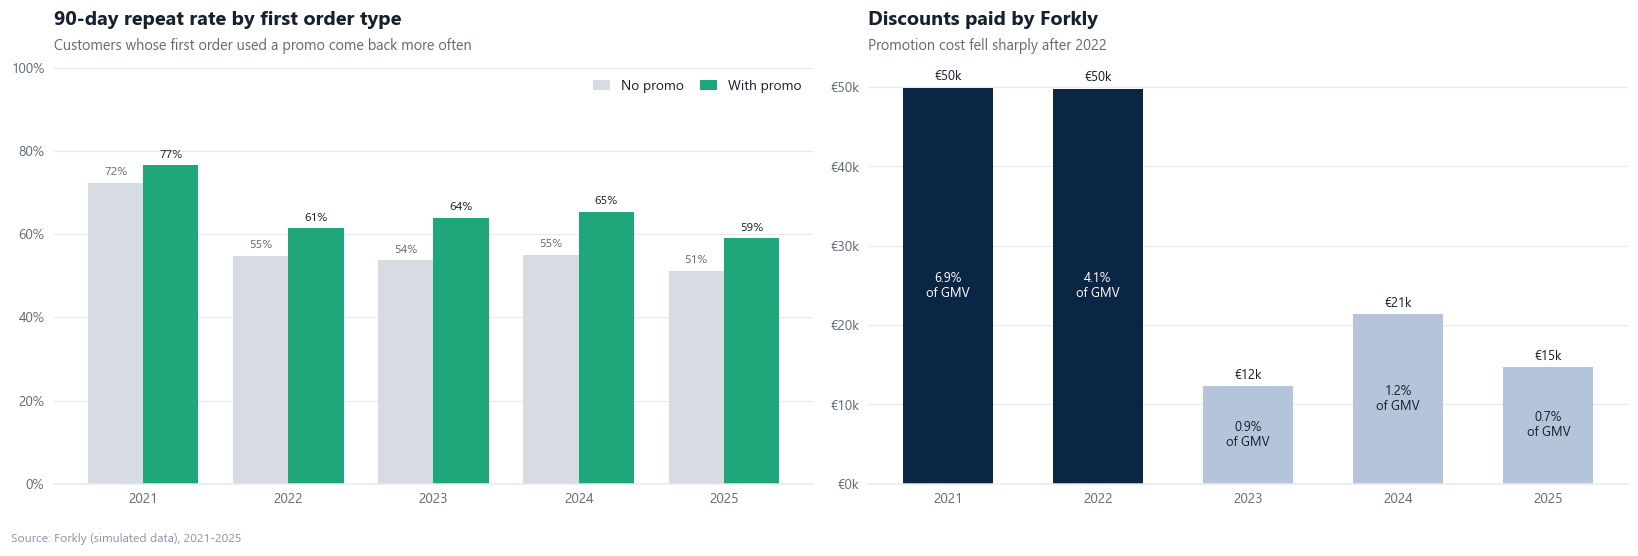

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(promo_repeat))
b1 = axes[0].bar(x - 0.19, promo_repeat["First order without promo"], width=0.38, color=GREY_LIGHT, label="No promo")
b2 = axes[0].bar(x + 0.19, promo_repeat["First order with promo"], width=0.38, color=GREEN, label="With promo")
label_bars(axes[0], b2, "{:.0f}%", fontsize=8)
label_bars(axes[0], b1, "{:.0f}%", fontsize=8, color=TEXT_MUTED)
axes[0].set_xticks(x, promo_repeat.index); axes[0].yaxis.set_major_formatter(pct); axes[0].set_ylim(0, 100)
legend_top(axes[0], ncol=2)
title(axes[0], "90-day repeat rate by first order type", "Customers whose first order used a promo come back more often")

bars = axes[1].bar(promo_cost.index, promo_cost["paid_by_forkly"],
                   color=[NAVY if y <= 2022 else NAVY_LIGHT for y in promo_cost.index], width=0.6)
label_bars(axes[1], bars, lambda v: f"€{v / 1e3:.0f}k")
for b, share in zip(bars, promo_cost["paid_by_forkly_%_gmv"]):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() / 2, f"{share:.1f}%\nof GMV", ha="center",
                 va="center", fontsize=8.5, color=BG if b.get_height() > 25000 else TEXT)
axes[1].yaxis.set_major_formatter(eur_k); axes[1].set_xticks(promo_cost.index)
title(axes[1], "Discounts paid by Forkly", "Promotion cost fell sharply after 2022")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_promotions.png")
plt.show()

## 7. What late deliveries cost

In [18]:
rated = done.dropna(subset=["delivery_rating", "minutes_vs_promise"]).copy()
bins = [-np.inf, -5, 0, 5, 10, 15, 20, np.inf]
labels = ["5+ min early", "0-5 early", "0-5 late", "5-10 late", "10-15 late", "15-20 late", "20+ late"]
rated["delay_bucket"] = pd.cut(rated["minutes_vs_promise"], bins=bins, labels=labels)
by_delay = rated.groupby("delay_bucket", observed=True).agg(reviews=("order_id", "size"),
                                                            delivery_rating=("delivery_rating", "mean"),
                                                            food_rating=("food_rating", "mean"))
by_delay.to_csv(TAB_DIR / "rating_by_delay.csv")
by_delay.round(2)

,reviews,delivery_rating,food_rating
delay_bucket,,,
5+ min early,48521,4.47,4.28
0-5 early,37365,4.43,4.25
0-5 late,24820,4.30,4.23
5-10 late,13958,3.50,4.07
10-15 late,5233,3.22,4.03
15-20 late,1857,2.90,4.01
20+ late,966,2.51,4.02


In [19]:
# does a late FIRST order make customers less likely to come back?
fo = (done.sort_values("order_datetime").groupby("customer_id").head(1)[["customer_id", "order_datetime", "is_late"]]
      .dropna(subset=["is_late"]))
fo = fo.join(second, on="customer_id")
fo["repeat_90d"] = (fo["second_order"] - fo["order_datetime"]).dt.days <= 90
fo = fo[fo["order_datetime"] < "2025-10-01"]
late_repeat = fo.groupby("is_late")["repeat_90d"].agg(["size", "mean"])
late_repeat["mean"] *= 100
late_repeat.index = ["On time", "Late"]
late_repeat.columns = ["customers", "repeat_90d_%"]
late_repeat.round(1)

,customers,repeat_90d_%
On time,33569,63.40
Late,6402,63.90


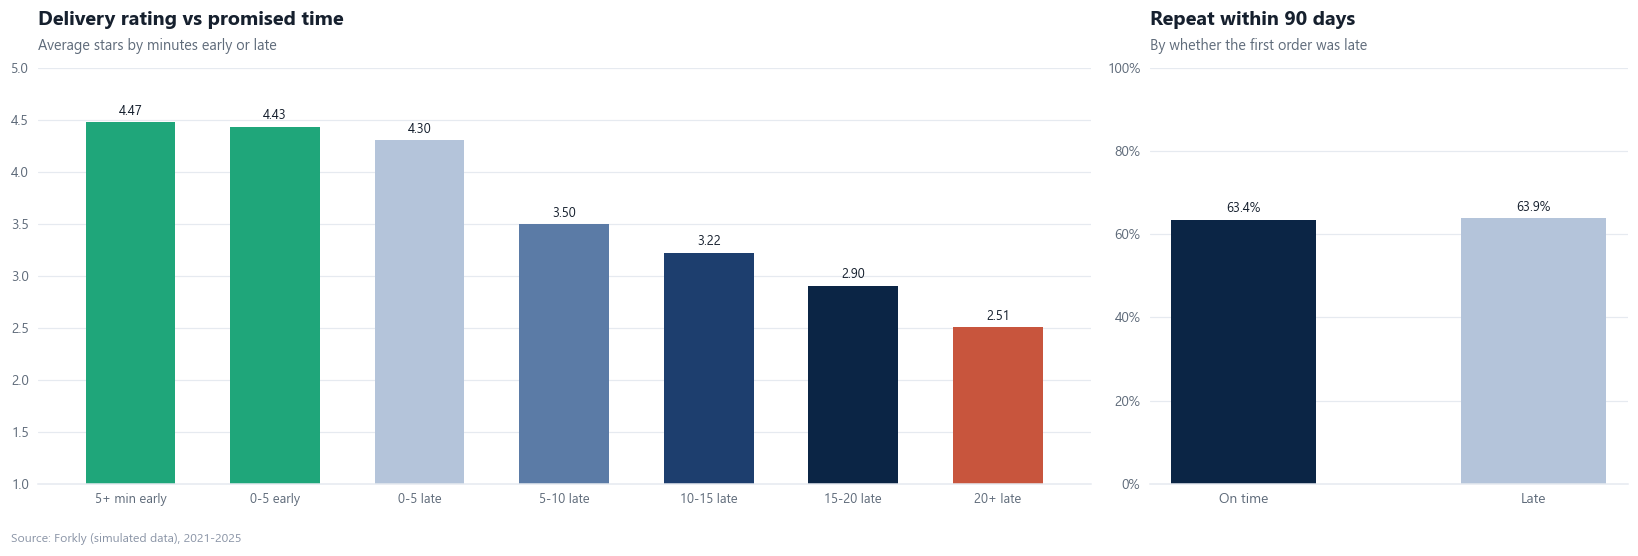

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
colors = [GREEN, GREEN, NAVY_LIGHT, STEEL, NAVY_2, NAVY, ALERT]
bars = axes[0].bar(by_delay.index.astype(str), by_delay["delivery_rating"], color=colors, width=0.62)
label_bars(axes[0], bars, "{:.2f}")
axes[0].set_ylim(1, 5); axes[0].tick_params(axis="x", labelsize=8.5)
title(axes[0], "Delivery rating vs promised time", "Average stars by minutes early or late")

bars = axes[1].bar(late_repeat.index, late_repeat["repeat_90d_%"], color=[NAVY, NAVY_LIGHT], width=0.5)
label_bars(axes[1], bars, "{:.1f}%")
axes[1].yaxis.set_major_formatter(pct); axes[1].set_ylim(0, 100)
title(axes[1], "Repeat within 90 days", "By whether the first order was late")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_late_cost.png")
plt.show()

In [21]:
# support load
tk = tickets.merge(orders[["order_id", "year"]], on="order_id")
support = tk.groupby("year").agg(tickets=("ticket_id", "size"), median_resolution_h=("resolution_hours", "median"),
                                 csat=("csat_score", "mean"), refunds=("refund_amount", "sum"),
                                 chatbot_share=("channel", lambda s: (s == "Chatbot").mean() * 100))
support["tickets_per_100_orders"] = support["tickets"] / kpi["orders"] * 100
support.to_csv(TAB_DIR / "support_by_year.csv")
support.round(2)

,tickets,median_resolution_h,csat,refunds,chatbot_share,tickets_per_100_orders
year,,,,,,
2021,1530,17.89,3.96,"4,765.00",0.00,4.25
2022,5344,31.08,3.48,"15,708.43",0.00,8.91
2023,2549,6.87,4.37,"9,671.84",36.17,4.18
2024,2150,2.34,4.50,"9,691.06",47.67,3.12
2025,1792,1.00,4.54,"8,249.55",57.92,2.42


## 8. Weather: more orders, more delays

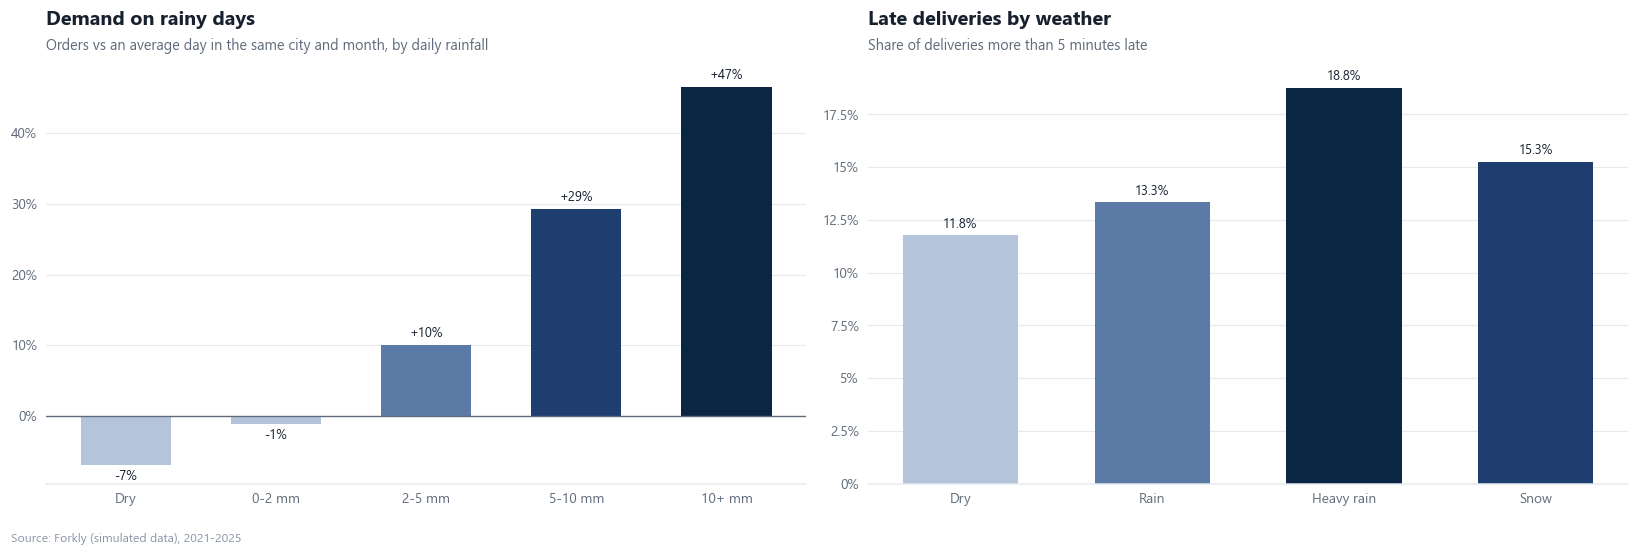

,size,mean
rain_bucket,,
Dry,9107,0.93
0-2 mm,1885,0.99
2-5 mm,1928,1.10
5-10 mm,1069,1.29
10+ mm,302,1.47


In [22]:
city_day = (orders.groupby(["order_date", "city_id"]).size().rename("orders").reset_index()
            .merge(weather, left_on=["order_date", "city_id"], right_on=["date", "city_id"], how="left"))
# compare each day with the average for that city and month, so city size and season don't hide the effect
city_day["ym"] = city_day["order_date"].dt.to_period("M")
city_day["demand_index"] = city_day["orders"] / city_day.groupby(["city_id", "ym"])["orders"].transform("mean")
city_day["rain_bucket"] = pd.cut(city_day["precip_mm"], [-0.1, 0, 2, 5, 10, 100],
                                 labels=["Dry", "0-2 mm", "2-5 mm", "5-10 mm", "10+ mm"])
weather_demand = city_day.groupby("rain_bucket", observed=True)["demand_index"].agg(["size", "mean"])

wl = done.merge(deliveries[["order_id", "weather_condition"]], on="order_id")
weather_late = wl.groupby("weather_condition")[["is_late", "delivery_minutes"]].mean()
weather_late["is_late"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
vals = (weather_demand["mean"] - 1) * 100
bars = axes[0].bar(vals.index.astype(str), vals.values, color=[NAVY_LIGHT, NAVY_LIGHT, STEEL, NAVY_2, NAVY], width=0.6)
label_bars(axes[0], bars, "{:+.0f}%")
zero_line(axes[0]); axes[0].yaxis.set_major_formatter(pct)
title(axes[0], "Demand on rainy days", "Orders vs an average day in the same city and month, by daily rainfall")

wlo = weather_late.reindex(["Dry", "Rain", "Heavy rain", "Snow"])
bars = axes[1].bar(wlo.index, wlo["is_late"], color=[NAVY_LIGHT, STEEL, NAVY, NAVY_2], width=0.6)
label_bars(axes[1], bars, "{:.1f}%")
axes[1].yaxis.set_major_formatter(pct)
title(axes[1], "Late deliveries by weather", "Share of deliveries more than 5 minutes late")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_weather.png")
plt.show()
weather_demand.round(3)

## 9. Marketing efficiency

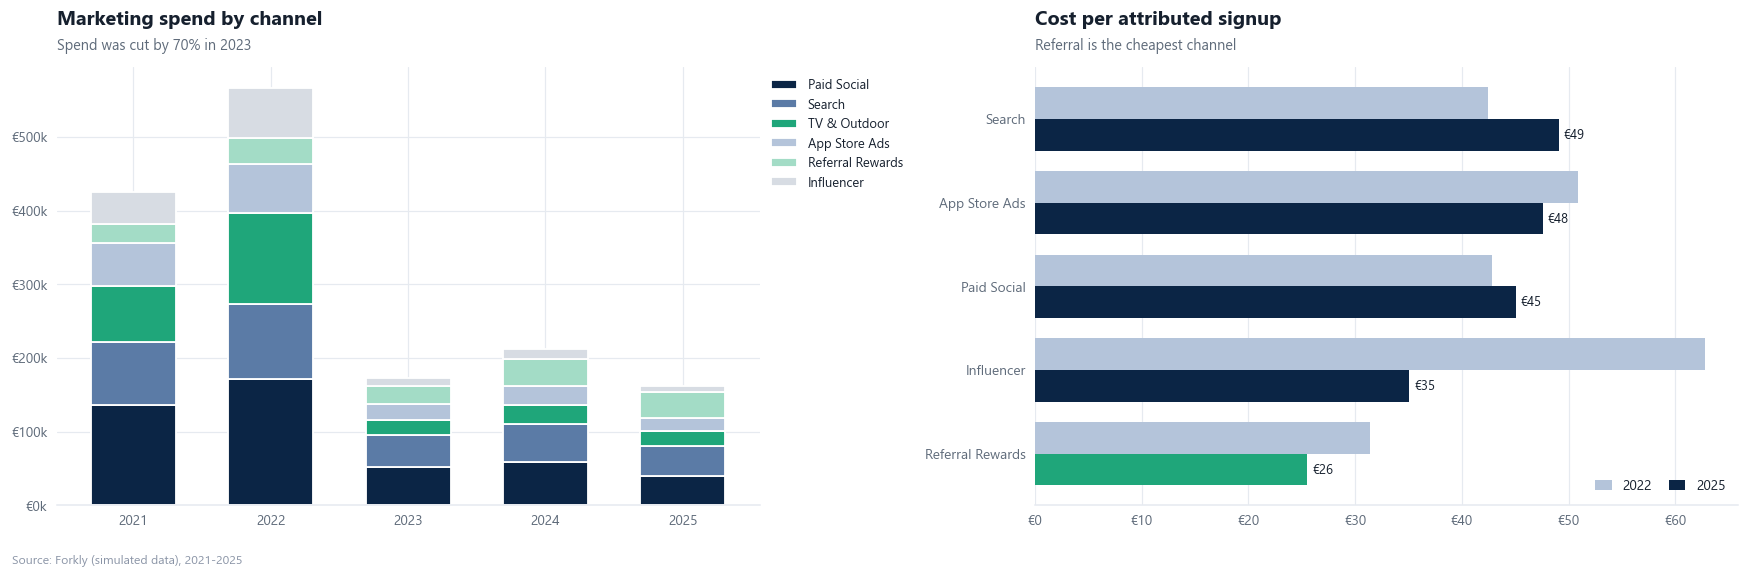

year,2021,2022,2023,2024,2025
channel,,,,,
App Store Ads,48.10,50.90,46.80,51.10,47.60
Influencer,49.80,62.70,29.40,35.50,35.10
Paid Social,41.00,42.80,48.00,43.40,45.10
Referral Rewards,28.30,31.40,25.60,26.10,25.50
Search,43.20,42.40,44.40,48.90,49.10


In [23]:
mk = mkt.assign(year=mkt["date"].dt.year)
channel_year = mk.groupby(["year", "channel"]).agg(spend=("spend_eur", "sum"), signups=("attributed_signups", "sum"),
                                                   clicks=("clicks", "sum"))
channel_year["cost_per_signup"] = channel_year["spend"] / channel_year["signups"].replace(0, np.nan)
channel_year.to_csv(TAB_DIR / "marketing_by_channel_year.csv")

cps = channel_year["cost_per_signup"].unstack("year").drop(index="TV & Outdoor", errors="ignore")
spend = channel_year["spend"].unstack("channel")
spend = spend[spend.sum().sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
spend.plot(kind="bar", stacked=True, ax=axes[0], width=0.62, edgecolor=BG, linewidth=1.2,
           color=[NAVY, STEEL, GREEN, NAVY_LIGHT, MINT, GREY_LIGHT])
axes[0].yaxis.set_major_formatter(eur_k); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(bbox_to_anchor=(1, 1), loc="upper left", fontsize=8.5)
title(axes[0], "Marketing spend by channel", "Spend was cut by 70% in 2023")

c = cps[[2022, 2025]].sort_values(2025, ascending=False)
y = np.arange(len(c))
axes[1].barh(y - 0.19, c[2022], height=0.38, color=NAVY_LIGHT, label="2022")
bars = axes[1].barh(y + 0.19, c[2025], height=0.38, color=[GREEN if i == "Referral Rewards" else NAVY for i in c.index],
                    label="2025")
label_hbars(axes[1], bars, lambda v: fmt_eur(v, 0))
axes[1].set_yticks(y, c.index); axes[1].invert_yaxis(); hbar_style(axes[1]); axes[1].xaxis.set_major_formatter(eur)
legend_top(axes[1], ncol=2, loc="lower right")
title(axes[1], "Cost per attributed signup", "Referral is the cheapest channel")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_marketing.png")
plt.show()
cps.round(1)

In [24]:
kpi[["marketing_spend", "new_customers", "cac"]].round(1)

,marketing_spend,new_customers,cac
2021,"425,558.80",12000,35.50
2022,"566,284.90",13000,43.60
2023,"172,649.40",6500,26.60
2024,"212,032.80",7500,28.30
2025,"161,899.50",6000,27.00


## 10. Cuisines and restaurants

In [25]:
cz = done.pivot_table(index="cuisine", columns="year", values="items_subtotal", aggfunc="sum", fill_value=0)
cz["growth_2023_2025_%"] = (cz[2025] / cz[2023].replace(0, np.nan) - 1) * 100
cz["share_2025_%"] = cz[2025] / cz[2025].sum() * 100
rating_c = done.groupby("cuisine")["food_rating"].mean().rename("avg_food_rating")
cz = cz.join(rating_c).sort_values(2025, ascending=False)
cz.to_csv(TAB_DIR / "cuisine_performance.csv")
cz[[2023, 2025, "growth_2023_2025_%", "share_2025_%", "avg_food_rating"]].round(1)

,2023,2025,growth_2023_2025_%,share_2025_%,avg_food_rating
cuisine,,,,,
Grocery,0.00,"346,738.40",NaN,17.00,4.30
Pizza,"242,847.70","269,944.90",11.20,13.20,4.20
Burgers,"200,480.30","245,553.70",22.50,12.00,4.20
Sushi,"207,118.40","239,015.00",15.40,11.70,4.20
Asian,"167,651.20","203,513.80",21.40,10.00,4.20
Italian,"105,979.60","135,172.90",27.50,6.60,4.20
Kebab,"97,432.80","124,358.00",27.60,6.10,4.20
Healthy/Salads,"92,141.00","107,463.60",16.60,5.30,4.20
Lithuanian/Local,"86,560.10","94,128.40",8.70,4.60,4.20


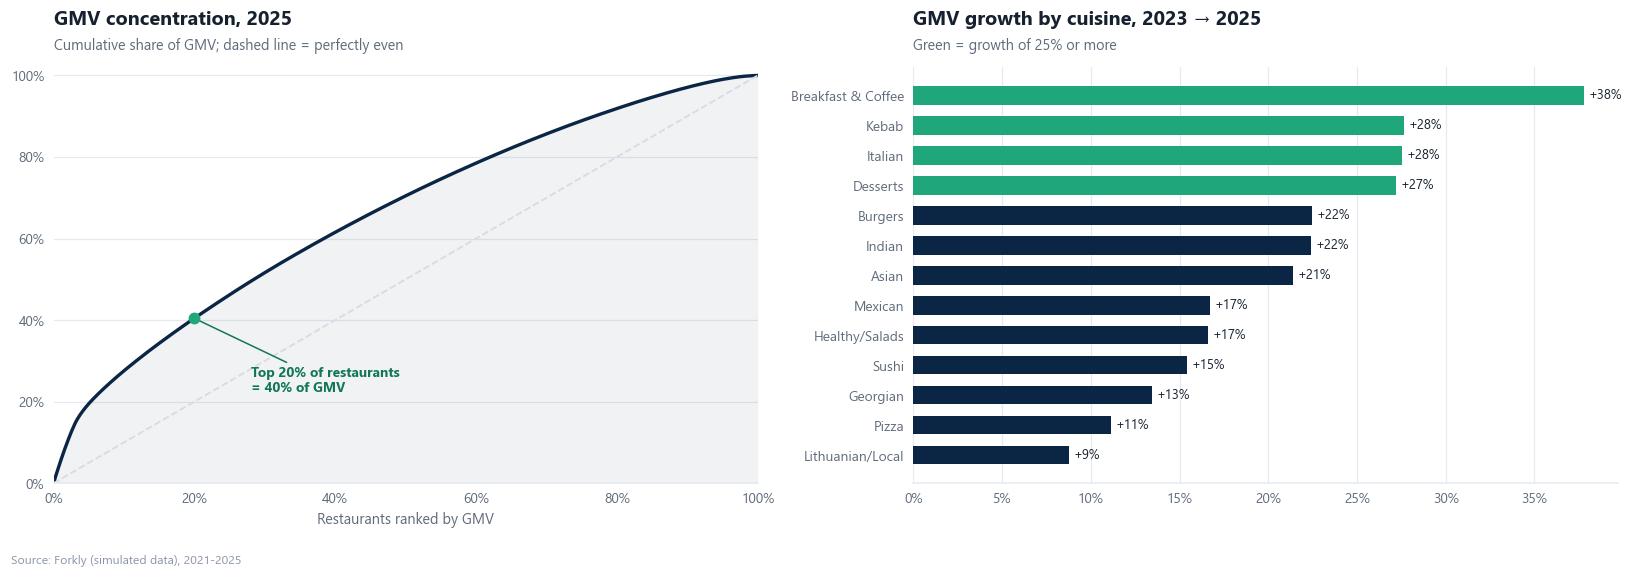

2,889 restaurants had orders in 2025


In [26]:
# Pareto: how concentrated is GMV across restaurants?
rest_gmv = done[done["year"] == 2025].groupby("restaurant_id")["items_subtotal"].sum().sort_values(ascending=False)
cum = rest_gmv.cumsum() / rest_gmv.sum() * 100
share_top20 = cum.iloc[int(len(cum) * 0.2) - 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
xs = np.arange(1, len(cum) + 1) / len(cum) * 100
axes[0].plot(xs, cum.values, color=NAVY)
axes[0].fill_between(xs, cum.values, color=NAVY, alpha=0.06)
axes[0].plot([0, 100], [0, 100], color=GREY_LIGHT, lw=1.2, ls="--")
axes[0].scatter([20], [share_top20], color=GREEN, s=60, zorder=4)
axes[0].annotate(f"Top 20% of restaurants\n= {share_top20:.0f}% of GMV", (20, share_top20), xytext=(28, share_top20 - 18),
                 fontsize=9, color=GREEN_DARK, weight="bold", arrowprops=dict(arrowstyle="-", color=GREEN_DARK, lw=1))
axes[0].xaxis.set_major_formatter(pct); axes[0].yaxis.set_major_formatter(pct)
axes[0].set_xlabel("Restaurants ranked by GMV"); axes[0].set_xlim(0, 100); axes[0].set_ylim(0, 102)
title(axes[0], "GMV concentration, 2025", "Cumulative share of GMV; dashed line = perfectly even")

g = cz["growth_2023_2025_%"].dropna().sort_values()
bars = axes[1].barh(g.index, g.values, color=[ALERT if v < 0 else (GREEN if v >= 25 else NAVY) for v in g.values], height=0.62)
label_hbars(axes[1], bars, "{:+.0f}%")
hbar_style(axes[1]); axes[1].xaxis.set_major_formatter(pct)
title(axes[1], "GMV growth by cuisine, 2023 → 2025", "Green = growth of 25% or more")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "03_restaurants.png")
plt.show()
print(f"{len(rest_gmv):,} restaurants had orders in 2025")

## 11. Customer segments (RFM, as of 31 Dec 2025)
**R**ecency = days since last order, **F**requency = orders in the last 12 months, **M**onetary = GMV in the last 12 months. Each is scored 1-5 by quintile.

In [27]:
snapshot = pd.Timestamp("2026-01-01")
last12 = done[done["order_datetime"] >= snapshot - pd.DateOffset(months=12)]
rfm = pd.DataFrame({
    "recency_days": (snapshot - done.groupby("customer_id")["order_datetime"].max()).dt.days,
    "frequency": last12.groupby("customer_id").size(),
    "monetary": last12.groupby("customer_id")["items_subtotal"].sum(),
}).fillna({"frequency": 0, "monetary": 0})

rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4:
        return "Champions"
    if r.R >= 3 and r.F >= 3:
        return "Loyal"
    if r.R >= 4 and r.F <= 2:
        return "New / promising"
    if r.R == 3:
        return "Needs attention"
    if r.R <= 2 and r.F >= 3:
        return "At risk"
    return "Lost / inactive"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("R", "size"), avg_recency_days=("recency_days", "mean"),
                                 avg_orders_12m=("frequency", "mean"), gmv_12m=("monetary", "sum"))
seg["customers_%"] = seg["customers"] / seg["customers"].sum() * 100
seg["gmv_%"] = seg["gmv_12m"] / seg["gmv_12m"].sum() * 100
seg = seg.sort_values("gmv_12m", ascending=False)
seg.to_csv(TAB_DIR / "rfm_segments.csv")
rfm.to_csv(TAB_DIR / "rfm_customers.csv")
seg.round(1)

,customers,avg_recency_days,avg_orders_12m,gmv_12m,customers_%,gmv_%
segment,,,,,,
Champions,12418,41.70,4.00,"1,405,229.80",29.70,68.90
Loyal,10178,154.80,1.50,"454,340.70",24.30,22.30
At risk,2527,321.30,1.20,"85,555.90",6.00,4.20
New / promising,1269,55.40,1.00,"37,119.10",3.00,1.80
Needs attention,1258,209.70,1.00,"36,528.10",3.00,1.80
Lost / inactive,14222,678.80,0.10,"22,086.40",34.00,1.10


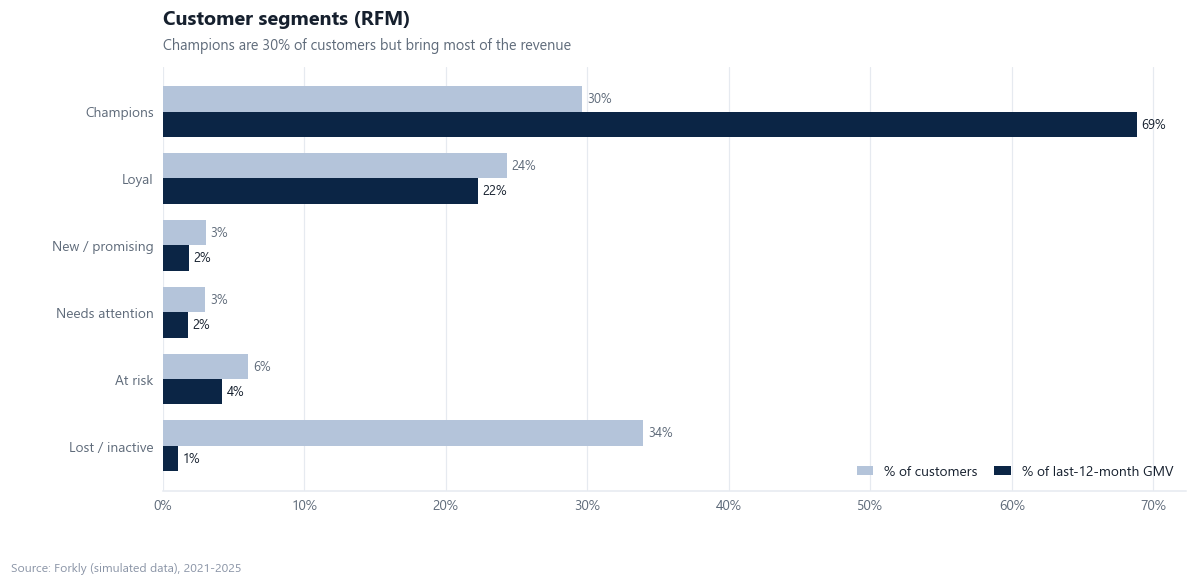

In [28]:
seg_order = ["Champions", "Loyal", "New / promising", "Needs attention", "At risk", "Lost / inactive"]
sp = seg.reindex(seg_order)

fig, ax = plt.subplots(figsize=(12, 5))
y = np.arange(len(sp))
b1 = ax.barh(y - 0.19, sp["customers_%"], height=0.38, color=NAVY_LIGHT, label="% of customers")
b2 = ax.barh(y + 0.19, sp["gmv_%"], height=0.38, color=NAVY,
             label="% of last-12-month GMV")
label_hbars(ax, b1, "{:.0f}%", color=TEXT_MUTED)
label_hbars(ax, b2, "{:.0f}%")
ax.set_yticks(y, sp.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct); hbar_style(ax)
legend_top(ax, ncol=2, loc="lower right")
title(ax, "Customer segments (RFM)", "Champions are 30% of customers but bring most of the revenue")
source_note(fig)
save_fig(fig, FIG_DIR / "03_rfm.png")
plt.show()

## 12. Key findings

- **Growth came from new cities.** GMV grew from €0.73M (2021) to €2.04M (2025), but the four launch cities have been flat at about €0.7M a year since 2023. Expansion cities made up 66% of 2025 GMV, so the next phase of growth depends on new markets or on getting more from existing customers.
- **2022 was the operational low point.** Late deliveries jumped to 32%, the delivery rating fell to 3.74, cancellations hit 9.3% and support tickets doubled to almost 9 per 100 orders. Every one of these measures recovered in 2023 and kept improving through 2025 (5.1% late, rating 4.51, 3.6% cancelled).
- **The move from losses to profit came from spending less on discounts and earning more per order.** Contribution per order went from -€1.03 (2021) to +€1.83 (2025). The biggest drivers were lower Forkly-paid discounts (+€1.28 per order), higher commission from bigger baskets (+€1.19) and the service fee (+€0.91). Courier pay per order barely changed.
- **Forkly Plus increases orders but reduces the margin on each order.** In 2025, Plus members ordered 3.9 times compared with 1.8 for non-members, with the same basket size. Free delivery lowered the average delivery fee from €2.35 to €1.85 per order, which is why contribution margin dipped from 7.7% to 6.4% of GMV in 2025 even as GMV grew. Before subscription fees, each Plus member brings less contribution than a non-member (€3.77 vs €5.01).
- **Being on time matters for ratings.** Deliveries that arrive early or up to 5 minutes late average 4.3-4.5 stars. Deliveries 20+ minutes late average 2.5 stars. In this data, a late first order does not change the 90-day repeat rate (63.9% vs 63.4%), so the cost shows up in ratings and support tickets rather than lost customers.
- **Promotions now cost little and still help retention.** Forkly-paid discounts fell from 6.9% of GMV (2021) to 0.7% (2025). Customers whose first order used a promo were 6-10 points more likely to order again within 90 days.
- **Referral is the cheapest channel.** It costs about €26 per attributed signup, against €45-49 for search, paid social and app store ads. Overall CAC fell from €43.6 in 2022 to €27.0 in 2025 after the spending cuts.
- **Rain is good for demand and bad for punctuality.** Days with 10+ mm of rain have 47% more orders than a normal day in the same city and month. Heavy rain raises the late rate from 11.8% to 18.8%.
- **A small group of customers drives most revenue.** Champions are 30% of customers but bring 69% of the last 12 months' GMV. 34% of customers are lost or inactive.
- **Groceries are now the biggest single category.** Two years after launch, groceries are 17% of 2025 GMV with a €30 basket, compared with about €28 for restaurant orders.